# SPRINT 2: MODEL DEVELOPMENT

This notebook completes the Sprint 2 workflow for predicting:

- `h1n1_vaccine`
- `seasonal_vaccine`

The notebook is divided into clear stages:

1. Load and inspect the cleaned data
2. Create engineered features
3. Verify the engineered features
4. Separate predictors and targets
5. Split training and validation data
6. Build the preprocessing pipeline
7. Train baseline models
8. Apply cross-validation
9. Tune model settings
10. Evaluate and compare models
11. Interpret important predictors
12. Save the deliverables

# Import the required libraries

These libraries provide data handling, preprocessing, modelling, evaluation, visualisation and model-saving tools.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from joblib import dump

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

RANDOM_STATE = 42

DATA_DIR = Path("../data_cleaned")
MODEL_DIR = Path("../models")
RESULTS_DIR = Path("../results")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

# Load and inspect the cleaned training data

The cleaned file contains the original predictors, respondent ID and both target variables. Some missing categorical values may be stored as the text `Unknown`; these are converted back to `NaN` so the pipeline can handle them consistently.

In [2]:
model_data_df = pd.read_csv(
    DATA_DIR / "train_clean.csv"
)

# Convert the text used for missing answers back to a real missing value.
model_data_df = model_data_df.replace("Unknown", np.nan)

print("Loaded data:", model_data_df.shape)
display(model_data_df.head())

Loaded data: (26707, 38)


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,doctor_recc_h1n1,doctor_recc_seasonal,chronic_med_condition,child_under_6_months,health_worker,health_insurance,opinion_h1n1_vacc_effective,opinion_h1n1_risk,opinion_h1n1_sick_from_vacc,opinion_seas_vacc_effective,opinion_seas_risk,opinion_seas_sick_from_vacc,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,hhs_geo_region,census_msa,household_adults,household_children,employment_industry,employment_occupation,h1n1_vaccine,seasonal_vaccine
0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,1,3,1,2,2,1,2,55 - 64 Years,< 12 Years,White,Female,Below Poverty,Not Married,Own,Not in Labor Force,oxchjgsf,Non-MSA,0,0,NaN,NaN,0,0
1,1,3,2,0,1,0,1,0,1,1,0,0,0,0,0,1,5,4,4,4,2,4,35 - 44 Years,12 Years,White,Male,Below Poverty,Not Married,Rent,Employed,bhuqouqj,"MSA, Not Principle City",0,0,pxcmvdjn,xgwztkwe,0,1
2,2,1,1,0,1,0,0,0,0,0,NaN,NaN,1,0,0,NaN,3,1,1,4,1,2,18 - 34 Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Not Married,Own,Employed,qufhixun,"MSA, Not Principle City",2,0,rucpziij,xtkaffoo,0,0
3,3,1,1,0,1,0,1,1,0,0,0,1,1,0,0,NaN,3,3,5,5,4,1,65+ Years,12 Years,White,Female,Below Poverty,Not Married,Rent,Not in Labor Force,lrircsnp,"MSA, Principle City",0,0,NaN,NaN,0,1
4,4,2,1,0,1,0,1,1,0,1,0,0,0,0,0,NaN,3,3,2,3,1,4,45 - 54 Years,Some College,White,Female,"<= $75,000, Above Poverty",Married,Own,Employed,qufhixun,"MSA, Not Principle City",1,0,wxleyezf,emcorrxb,0,0


In [3]:
# Columns that are not predictors.
identifier_column = "respondent_id"

target_columns = [
    "h1n1_vaccine",
    "seasonal_vaccine"
]

# The 35 original predictor columns.
original_predictor_columns = [
    column
    for column in model_data_df.columns
    if column not in [identifier_column] + target_columns
]

print("Original predictors:", len(original_predictor_columns))
print("Target variables:", target_columns)
print("Duplicate respondent IDs:", model_data_df[identifier_column].duplicated().sum())
print("Missing target values:")
print(model_data_df[target_columns].isna().sum())

Original predictors: 35
Target variables: ['h1n1_vaccine', 'seasonal_vaccine']
Duplicate respondent IDs: 0
Missing target values:
h1n1_vaccine        0
seasonal_vaccine    0
dtype: int64


##  Feature engineering

Feature engineering creates additional predictors from the original answers. These are candidate features: cross-validation and validation results will later show whether the models find them useful.

### 2.1 Convert numeric survey columns to numeric values

This conversion is a fixed data-formatting rule. It does not calculate anything from the full dataset, so it can safely happen before the train-validation split.

In [4]:
binary_columns = [
    "behavioral_antiviral_meds",
    "behavioral_avoidance",
    "behavioral_face_mask",
    "behavioral_wash_hands",
    "behavioral_large_gatherings",
    "behavioral_outside_home",
    "behavioral_touch_face",
    "doctor_recc_h1n1",
    "doctor_recc_seasonal",
    "chronic_med_condition",
    "child_under_6_months",
    "health_worker",
    "health_insurance"
]

scale_and_count_columns = [
    "h1n1_concern",
    "h1n1_knowledge",
    "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk",
    "opinion_h1n1_sick_from_vacc",
    "opinion_seas_vacc_effective",
    "opinion_seas_risk",
    "opinion_seas_sick_from_vacc",
    "household_adults",
    "household_children"
]

for column in binary_columns + scale_and_count_columns:
    model_data_df[column] = pd.to_numeric(
        model_data_df[column],
        errors="coerce"
    )

### 2.2 Count missing answers and create selected missingness flags

- `n_missing_answers` records how many original predictor answers are missing for each respondent.
- A selected flag equals `1` when that particular answer is missing and `0` when it was recorded.

In [5]:
# Count missing answers before any missing values are filled.
model_data_df["n_missing_answers"] = (
    model_data_df[original_predictor_columns]
    .isna()
    .sum(axis=1)
)

# Create selected 0/1 missingness flags.
missing_flag_columns = [
    "health_insurance",
    "doctor_recc_h1n1",
    "doctor_recc_seasonal",
    "income_poverty"
]

for column in missing_flag_columns:
    model_data_df[f"{column}_missing"] = (
        model_data_df[column]
        .isna()
        .astype(int)
    )

### 2.3 Create “Don’t know” indicators

For the six opinion questions, the value `3` means “Don’t know”, not a middle opinion. The flag preserves uncertainty, while the value `3` is changed to missing in the original opinion column so it is not treated as a normal midpoint.

In [6]:
opinion_columns = [
    "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk",
    "opinion_h1n1_sick_from_vacc",
    "opinion_seas_vacc_effective",
    "opinion_seas_risk",
    "opinion_seas_sick_from_vacc"
]

for column in opinion_columns:
    # 1 means the respondent selected "Don't know"; otherwise 0.
    model_data_df[f"{column}_dont_know"] = (
        model_data_df[column]
        .eq(3)
        .astype(int)
    )

    # Do not treat "Don't know" as the numerical middle of the scale.
    model_data_df[column] = model_data_df[column].replace(3, np.nan)

### 2.4 Create hypothesis-related scores and combined features

The scores summarize related survey answers:

- preventive behaviour;
- H1N1 risk perception;
- H1N1 and seasonal vaccine confidence;
- approximate household size;
- whether either vaccine was recommended;
- whether the respondent belongs to a broad health-risk/exposure group.

In [7]:
# Seven yes/no preventive-behaviour columns.
preventive_behavior_columns = [
    "behavioral_antiviral_meds",
    "behavioral_avoidance",
    "behavioral_face_mask",
    "behavioral_wash_hands",
    "behavioral_large_gatherings",
    "behavioral_outside_home",
    "behavioral_touch_face"
]

# Score from 0 to 7: higher means more reported preventive behaviours.
model_data_df["preventive_behavior_score"] = (
    model_data_df[preventive_behavior_columns]
    .sum(axis=1, min_count=1)
)

# Normalize concern from 0-3 to 0-1.
normalized_h1n1_concern = (
    model_data_df["h1n1_concern"] / 3
)

# Normalize the valid risk answers 1, 2, 4 and 5 to the 0-1 range.
normalized_h1n1_risk = (
    model_data_df["opinion_h1n1_risk"] - 1
) / 4

# Average the available concern and risk components.
model_data_df["h1n1_risk_perception_score"] = (
    pd.concat(
        [normalized_h1n1_concern, normalized_h1n1_risk],
        axis=1
    )
    .mean(axis=1)
)

# Vaccine effectiveness: higher values mean more confidence.
normalized_h1n1_effectiveness = (
    model_data_df["opinion_h1n1_vacc_effective"] - 1
) / 4

# Worry runs in the opposite direction, so subtract it from 1.
reversed_h1n1_worry = 1 - (
    (model_data_df["opinion_h1n1_sick_from_vacc"] - 1) / 4
)

model_data_df["h1n1_vaccine_confidence_score"] = (
    pd.concat(
        [normalized_h1n1_effectiveness, reversed_h1n1_worry],
        axis=1
    )
    .mean(axis=1)
)

# Repeat the confidence calculation for the seasonal vaccine.
normalized_seasonal_effectiveness = (
    model_data_df["opinion_seas_vacc_effective"] - 1
) / 4

reversed_seasonal_worry = 1 - (
    (model_data_df["opinion_seas_sick_from_vacc"] - 1) / 4
)

model_data_df["seasonal_vaccine_confidence_score"] = (
    pd.concat(
        [normalized_seasonal_effectiveness, reversed_seasonal_worry],
        axis=1
    )
    .mean(axis=1)
)

# The original household columns count other people, so add the respondent.
model_data_df["household_size"] = (
    model_data_df["household_adults"]
    + model_data_df["household_children"]
    + 1
)

# 1 means a doctor recommended at least one vaccine; 0 means neither.
model_data_df["any_doctor_recommendation"] = (
    model_data_df[
        ["doctor_recc_h1n1", "doctor_recc_seasonal"]
    ]
    .max(axis=1, skipna=True)
)

# If both recommendation answers are missing, the combined answer is unknown.
both_doctor_answers_missing = model_data_df[
    ["doctor_recc_h1n1", "doctor_recc_seasonal"]
].isna().all(axis=1)

model_data_df.loc[
    both_doctor_answers_missing,
    "any_doctor_recommendation"
] = np.nan

# Broad hypothesis-driven indicator: older, chronically ill or health worker.
model_data_df["high_risk_or_exposed"] = (
    model_data_df["age_group"].eq("65+ Years")
    | model_data_df["chronic_med_condition"].eq(1)
    | model_data_df["health_worker"].eq(1)
).astype(int)

## STAGE 3: Verify the engineered features

This quality-control stage checks that every expected feature exists, reports missing values and tests whether the main scores stay inside their intended ranges.

In [8]:
engineered_features = [
    "n_missing_answers",
    "health_insurance_missing",
    "doctor_recc_h1n1_missing",
    "doctor_recc_seasonal_missing",
    "income_poverty_missing",
    *[f"{column}_dont_know" for column in opinion_columns],
    "preventive_behavior_score",
    "h1n1_risk_perception_score",
    "h1n1_vaccine_confidence_score",
    "seasonal_vaccine_confidence_score",
    "household_size",
    "any_doctor_recommendation",
    "high_risk_or_exposed"
]

missing_engineered_features = [
    feature
    for feature in engineered_features
    if feature not in model_data_df.columns
]

print("Missing engineered features:", missing_engineered_features)
print("Number of engineered features:", len(engineered_features))

feature_summary = model_data_df[engineered_features].describe().T

feature_summary["missing_count"] = (
    model_data_df[engineered_features]
    .isna()
    .sum()
)

display(feature_summary)

Missing engineered features: []
Number of engineered features: 18


,count,mean,std,min,25%,50%,75%,max,missing_count
n_missing_answers,26707.0,2.275134,2.854102,0.0,1.000000,2.000000,3.000000,22.0,0
health_insurance_missing,26707.0,0.459580,0.498373,0.0,0.000000,0.000000,1.000000,1.0,0
doctor_recc_h1n1_missing,26707.0,0.080878,0.272652,0.0,0.000000,0.000000,0.000000,1.0,0
doctor_recc_seasonal_missing,26707.0,0.080878,0.272652,0.0,0.000000,0.000000,0.000000,1.0,0
income_poverty_missing,26707.0,0.165612,0.371739,0.0,0.000000,0.000000,0.000000,1.0,0
opinion_h1n1_vacc_effective_dont_know,26707.0,0.176845,0.381545,0.0,0.000000,0.000000,0.000000,1.0,0
opinion_h1n1_risk_dont_know,26707.0,0.041824,0.200191,0.0,0.000000,0.000000,0.000000,1.0,0
opinion_h1n1_sick_from_vacc_dont_know,26707.0,0.005542,0.074237,0.0,0.000000,0.000000,0.000000,1.0,0
opinion_seas_vacc_effective_dont_know,26707.0,0.045531,0.208470,0.0,0.000000,0.000000,0.000000,1.0,0
opinion_seas_risk_dont_know,26707.0,0.025349,0.157186,0.0,0.000000,0.000000,0.000000,1.0,0


In [9]:
# Expected minimum and maximum for the main engineered features.
range_checks = {
    "preventive_behavior_score": (0, 7),
    "h1n1_risk_perception_score": (0, 1),
    "h1n1_vaccine_confidence_score": (0, 1),
    "seasonal_vaccine_confidence_score": (0, 1),
    "household_size": (1, 7),
    "any_doctor_recommendation": (0, 1),
    "high_risk_or_exposed": (0, 1)
}

for feature, (minimum, maximum) in range_checks.items():
    is_valid = (
        model_data_df[feature]
        .dropna()
        .between(minimum, maximum)
        .all()
    )

    print(f"{feature}: {is_valid}")

preventive_behavior_score: True
h1n1_risk_perception_score: True
h1n1_vaccine_confidence_score: True
seasonal_vaccine_confidence_score: True
household_size: True
any_doctor_recommendation: True
high_risk_or_exposed: True


## STAGE 4: Separate predictors and target variables

`X` contains the original and engineered predictors. The respondent ID and the two outcomes are excluded. Each outcome is stored as a separate target because this project trains a separate classifier for each vaccine.

In [10]:
X = model_data_df.drop(
    columns=[
        "respondent_id",
        "h1n1_vaccine",
        "seasonal_vaccine"
    ]
)

y_h1n1 = model_data_df["h1n1_vaccine"].astype(int)
y_seasonal = model_data_df["seasonal_vaccine"].astype(int)

print("Predictor data:", X.shape)
print("H1N1 target:", y_h1n1.shape)
print("Seasonal target:", y_seasonal.shape)
print("Targets accidentally present in X:", set(target_columns).intersection(X.columns))

Predictor data: (26707, 53)
H1N1 target: (26707,)
Seasonal target: (26707,)
Targets accidentally present in X: set()


## STAGE 5: Split the training and validation data

- 80% of respondents are used for training.
- 20% are kept untouched for final validation.
- Stratification preserves the four combinations of the two vaccination outcomes.

In [11]:
combined_target = (
    y_h1n1.astype(str)
    + "_"
    + y_seasonal.astype(str)
)

(
    X_train,
    X_valid,
    y_h1n1_train,
    y_h1n1_valid,
    y_seasonal_train,
    y_seasonal_valid
) = train_test_split(
    X,
    y_h1n1,
    y_seasonal,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=combined_target
)

print("Training predictors:", X_train.shape)
print("Validation predictors:", X_valid.shape)
print("H1N1 training target:", y_h1n1_train.shape)
print("Seasonal training target:", y_seasonal_train.shape)

Training predictors: (21365, 53)
Validation predictors: (5342, 53)
H1N1 training target: (21365,)
Seasonal training target: (21365,)


## STAGE 6: Build the preprocessing pipeline

Each predictor type needs different preparation:

- numeric: median imputation and standardization;
- ordinal: most-common imputation and order-preserving encoding;
- nominal: `Unknown` imputation and one-hot encoding.

The preprocessing rules are fitted only on training data when a model pipeline is trained.

In [12]:
# Ordered categorical predictors.
ordinal_columns = [
    "age_group",
    "education",
    "income_poverty"
]

# Unordered categorical predictors.
nominal_columns = [
    "race",
    "sex",
    "marital_status",
    "rent_or_own",
    "employment_status",
    "census_msa",
    "hhs_geo_region",
    "employment_industry",
    "employment_occupation"
]

# Every remaining predictor is numeric.
numeric_columns = [
    column
    for column in X.columns
    if column not in ordinal_columns + nominal_columns
]

print("Numeric columns:", len(numeric_columns))
print("Ordinal columns:", len(ordinal_columns))
print("Nominal columns:", len(nominal_columns))
print("Total grouped columns:", len(numeric_columns + ordinal_columns + nominal_columns))
print("Total X columns:", X.shape[1])

Numeric columns: 41
Ordinal columns: 3
Nominal columns: 9
Total grouped columns: 53
Total X columns: 53


In [13]:
# Numeric rules: fill missing values using the training median, then scale.
numeric_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Correct order for the three ordinal predictors.
age_order = [
    "18 - 34 Years",
    "35 - 44 Years",
    "45 - 54 Years",
    "55 - 64 Years",
    "65+ Years"
]

education_order = [
    "< 12 Years",
    "12 Years",
    "Some College",
    "College Graduate"
]

income_order = [
    "Below Poverty",
    "<= $75,000, Above Poverty",
    "> $75,000"
]

# Ordinal rules: fill missing categories, then preserve their natural order.
ordinal_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OrdinalEncoder(
                categories=[
                    age_order,
                    education_order,
                    income_order
                ],
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )
        )
    ]
)

# Nominal rules: create an Unknown category, then one-hot encode.
# Dense output works with all three selected model families.
nominal_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

# Send each group through its own transformation rules.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_preprocessor,
            numeric_columns
        ),
        (
            "ordinal",
            ordinal_preprocessor,
            ordinal_columns
        ),
        (
            "nominal",
            nominal_preprocessor,
            nominal_columns
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


## STAGE 7: Define the baseline classification models

Three model families are compared:

- Logistic Regression: interpretable linear baseline;
- Random Forest: captures non-linear patterns and interactions;
- Gradient Boosting: builds a sequence of trees that correct earlier errors.

Each model is attached to its own copy of the preprocessor.

In [14]:
baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}


def make_model_pipeline(model):
    # Combine an independent preprocessor with one classifier.

    return Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model))
        ]
    )


print("Baseline models:", list(baseline_models))

Baseline models: ['Logistic Regression', 'Random Forest', 'Gradient Boosting']


## STAGE 8: Cross-validation on the training data

Cross-validation divides the training portion into several temporary folds. Each model trains and validates repeatedly, producing a more stable performance estimate than a single split.

The untouched 20% validation set is not used here.

In [15]:
scoring_metrics = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

training_targets = {
    "H1N1": y_h1n1_train,
    "Seasonal": y_seasonal_train
}

cv_rows = []

for target_name, y_train in training_targets.items():
    for model_name, model in baseline_models.items():
        model_pipeline = make_model_pipeline(model)

        cv_scores = cross_validate(
            model_pipeline,
            X_train,
            y_train,
            cv=5,
            scoring=scoring_metrics,
            n_jobs=-1
        )

        cv_rows.append(
            {
                "Target": target_name,
                "Model": model_name,
                "CV ROC-AUC": cv_scores["test_roc_auc"].mean(),
                "CV Accuracy": cv_scores["test_accuracy"].mean(),
                "CV Precision": cv_scores["test_precision"].mean(),
                "CV Recall": cv_scores["test_recall"].mean(),
                "CV F1": cv_scores["test_f1"].mean()
            }
        )

        print(f"Completed: {target_name} - {model_name}")

cv_results_df = (
    pd.DataFrame(cv_rows)
    .sort_values(["Target", "CV ROC-AUC"], ascending=[True, False])
    .reset_index(drop=True)
)

display(cv_results_df.round(3))

Completed: H1N1 - Logistic Regression
Completed: H1N1 - Random Forest
Completed: H1N1 - Gradient Boosting
Completed: Seasonal - Logistic Regression
Completed: Seasonal - Random Forest
Completed: Seasonal - Gradient Boosting


,Target,Model,CV ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1
0,H1N1,Gradient Boosting,0.865,0.855,0.742,0.484,0.586
1,H1N1,Logistic Regression,0.860,0.852,0.721,0.494,0.586
2,H1N1,Random Forest,0.854,0.851,0.775,0.424,0.548
3,Seasonal,Gradient Boosting,0.861,0.788,0.782,0.755,0.768
4,Seasonal,Logistic Regression,0.855,0.780,0.774,0.747,0.760
5,Seasonal,Random Forest,0.854,0.781,0.776,0.745,0.760


### Learning from baseline cross-validation

- Gradient Boosting achieved the highest mean ROC-AUC for both H1N1
  vaccination (0.865) and seasonal vaccination (0.861).

- Logistic Regression performed only slightly below Gradient Boosting,
  suggesting that a relatively simple and interpretable model can capture
  much of the predictive relationship.

- Random Forest achieved the highest H1N1 precision (0.775), but had the
  lowest H1N1 recall (0.424), meaning that its positive predictions were
  often correct, but it missed many vaccinated respondents.

- All H1N1 models had high accuracy but relatively low recall. This is
  partly explained by the class imbalance in the H1N1 target, demonstrating
  why accuracy should not be interpreted on its own.

- The seasonal-vaccine models produced a better balance between precision
  and recall. Gradient Boosting achieved the strongest seasonal F1 score
  of 0.768.

- The performance differences between the three models were small.
  Hyperparameter tuning and evaluation on the untouched validation set
  are required before selecting the final models.

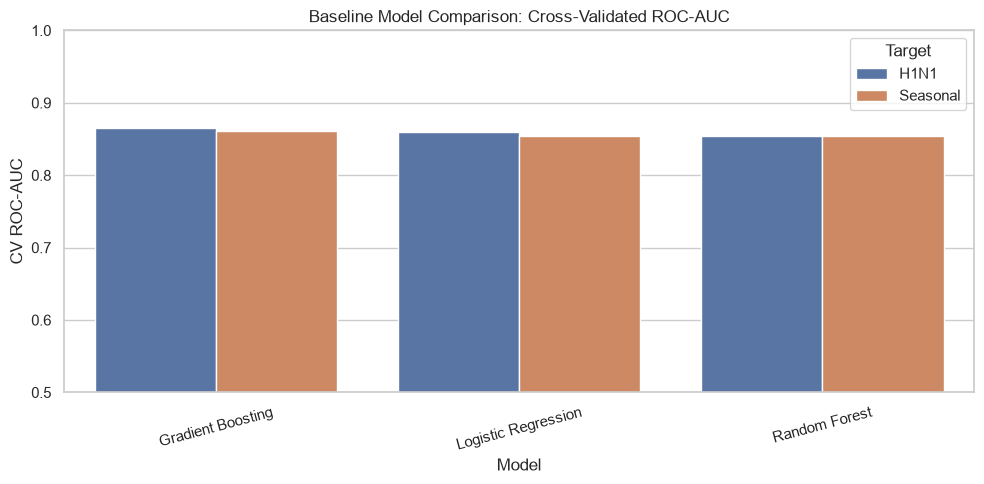

In [16]:
# Compare baseline ROC-AUC scores visually.
plt.figure(figsize=(10, 5))

sns.barplot(
    data=cv_results_df,
    x="Model",
    y="CV ROC-AUC",
    hue="Target"
)

plt.title("Baseline Model Comparison: Cross-Validated ROC-AUC")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## STAGE 9: Hyperparameter tuning

Hyperparameters are model settings chosen before training. `RandomizedSearchCV` tries a small selection of settings using three-fold cross-validation and selects the combination with the highest ROC-AUC.

This notebook tunes all three model families for both targets. Reduce `N_TUNING_ITERATIONS` if the computer takes too long.

In [17]:
parameter_distributions = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "model__n_estimators": [150, 250, 400],
        "model__max_depth": [None, 8, 15, 25],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__max_features": ["sqrt", "log2"],
        "model__class_weight": [None, "balanced"]
    },
    "Gradient Boosting": {
        "model__n_estimators": [75, 100, 150, 200],
        "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
        "model__max_depth": [1, 2, 3],
        "model__min_samples_leaf": [1, 5, 10]
    }
}

N_TUNING_ITERATIONS = 8

best_models = {}
tuning_rows = []

for target_name, y_train in training_targets.items():
    best_models[target_name] = {}

    for model_name, model in baseline_models.items():
        search = RandomizedSearchCV(
            estimator=make_model_pipeline(model),
            param_distributions=parameter_distributions[model_name],
            n_iter=N_TUNING_ITERATIONS,
            scoring="roc_auc",
            cv=3,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            refit=True
        )

        search.fit(X_train, y_train)

        best_models[target_name][model_name] = search.best_estimator_

        tuning_rows.append(
            {
                "Target": target_name,
                "Model": model_name,
                "Best tuning ROC-AUC": search.best_score_,
                "Best parameters": search.best_params_
            }
        )

        print(f"Tuned: {target_name} - {model_name}")

tuning_results_df = (
    pd.DataFrame(tuning_rows)
    .sort_values(
        ["Target", "Best tuning ROC-AUC"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(tuning_results_df)

Tuned: H1N1 - Logistic Regression
Tuned: H1N1 - Random Forest
Tuned: H1N1 - Gradient Boosting
Tuned: Seasonal - Logistic Regression
Tuned: Seasonal - Random Forest
Tuned: Seasonal - Gradient Boosting


,Target,Model,Best tuning ROC-AUC,Best parameters
0,H1N1,Gradient Boosting,0.866106,"{'model__n_estimators': 75, 'model__min_sample..."
1,H1N1,Logistic Regression,0.860895,"{'model__class_weight': None, 'model__C': 0.1}"
2,H1N1,Random Forest,0.858656,"{'model__n_estimators': 150, 'model__min_sampl..."
3,Seasonal,Gradient Boosting,0.860556,"{'model__n_estimators': 75, 'model__min_sample..."
4,Seasonal,Random Forest,0.854411,"{'model__n_estimators': 250, 'model__min_sampl..."
5,Seasonal,Logistic Regression,0.854383,"{'model__class_weight': None, 'model__C': 0.1}"


## STAGE 10: Evaluate tuned models on the untouched validation data

- Class predictions use a default probability threshold of 0.50.
- ROC-AUC uses predicted probabilities and is the primary comparison metric.
- Accuracy, precision, recall and F1 describe different aspects of classification performance.

In [18]:
validation_targets = {
    "H1N1": y_h1n1_valid,
    "Seasonal": y_seasonal_valid
}

validation_rows = []

for target_name, y_valid in validation_targets.items():
    for model_name, fitted_pipeline in best_models[target_name].items():
        predicted_class = fitted_pipeline.predict(X_valid)
        predicted_probability = fitted_pipeline.predict_proba(X_valid)[:, 1]

        validation_rows.append(
            {
                "Target": target_name,
                "Model": model_name,
                "ROC-AUC": roc_auc_score(y_valid, predicted_probability),
                "Accuracy": accuracy_score(y_valid, predicted_class),
                "Precision": precision_score(y_valid, predicted_class, zero_division=0),
                "Recall": recall_score(y_valid, predicted_class, zero_division=0),
                "F1": f1_score(y_valid, predicted_class, zero_division=0)
            }
        )

validation_results_df = (
    pd.DataFrame(validation_rows)
    .sort_values(["Target", "ROC-AUC"], ascending=[True, False])
    .reset_index(drop=True)
)

display(validation_results_df.round(3))

,Target,Model,ROC-AUC,Accuracy,Precision,Recall,F1
0,H1N1,Gradient Boosting,0.873,0.855,0.730,0.500,0.594
1,H1N1,Logistic Regression,0.867,0.849,0.707,0.496,0.583
2,H1N1,Random Forest,0.866,0.808,0.534,0.741,0.621
3,Seasonal,Gradient Boosting,0.861,0.787,0.779,0.757,0.768
4,Seasonal,Logistic Regression,0.857,0.783,0.774,0.754,0.764
5,Seasonal,Random Forest,0.854,0.782,0.774,0.752,0.763


In [19]:
# Identify the best validation model for each target using ROC-AUC.
best_model_names = (
    validation_results_df
    .loc[
        validation_results_df.groupby("Target")["ROC-AUC"].idxmax(),
        ["Target", "Model", "ROC-AUC"]
    ]
    .reset_index(drop=True)
)

display(best_model_names.round(3))

,Target,Model,ROC-AUC
0,H1N1,Gradient Boosting,0.873
1,Seasonal,Gradient Boosting,0.861


### 10.1 Confusion matrices for the best models

The confusion matrix shows true negatives, false positives, false negatives and true positives at the 0.50 threshold.

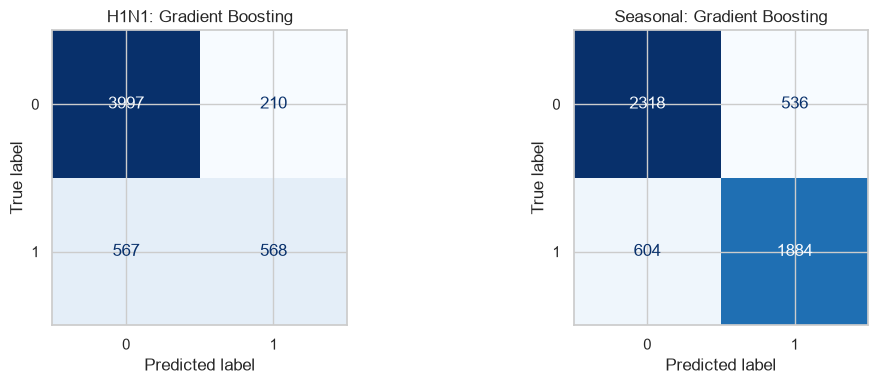

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for axis, target_name in zip(axes, ["H1N1", "Seasonal"]):
    model_name = best_model_names.loc[
        best_model_names["Target"].eq(target_name),
        "Model"
    ].iloc[0]

    fitted_pipeline = best_models[target_name][model_name]
    y_valid = validation_targets[target_name]
    predicted_class = fitted_pipeline.predict(X_valid)

    ConfusionMatrixDisplay.from_predictions(
        y_valid,
        predicted_class,
        ax=axis,
        cmap="Blues",
        colorbar=False
    )

    axis.set_title(f"{target_name}: {model_name}")

plt.tight_layout()
plt.show()

### 10.2 ROC curves for the best models

The ROC curve examines model performance across all possible classification thresholds.

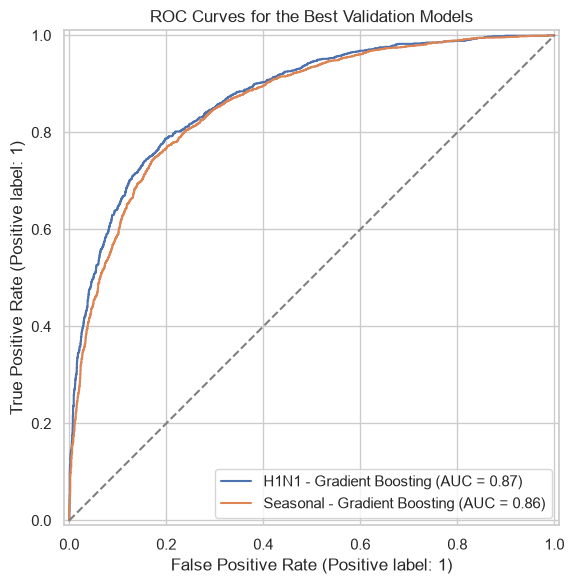

In [21]:
fig, axis = plt.subplots(figsize=(7, 6))

for target_name in ["H1N1", "Seasonal"]:
    model_name = best_model_names.loc[
        best_model_names["Target"].eq(target_name),
        "Model"
    ].iloc[0]

    fitted_pipeline = best_models[target_name][model_name]

    RocCurveDisplay.from_estimator(
        fitted_pipeline,
        X_valid,
        validation_targets[target_name],
        name=f"{target_name} - {model_name}",
        ax=axis
    )

axis.plot([0, 1], [0, 1], linestyle="--", color="grey")
axis.set_title("ROC Curves for the Best Validation Models")
plt.tight_layout()
plt.show()

### 10.3 Detailed classification reports

These reports show class-level precision, recall and F1. Class `1` represents vaccinated respondents.

In [22]:
for target_name in ["H1N1", "Seasonal"]:
    model_name = best_model_names.loc[
        best_model_names["Target"].eq(target_name),
        "Model"
    ].iloc[0]

    fitted_pipeline = best_models[target_name][model_name]
    predicted_class = fitted_pipeline.predict(X_valid)

    print(f"\n{target_name} - {model_name}")
    print(
        classification_report(
            validation_targets[target_name],
            predicted_class,
            digits=3,
            zero_division=0
        )
    )


H1N1 - Gradient Boosting
              precision    recall  f1-score   support

           0      0.876     0.950     0.911      4207
           1      0.730     0.500     0.594      1135

    accuracy                          0.855      5342
   macro avg      0.803     0.725     0.753      5342
weighted avg      0.845     0.855     0.844      5342


Seasonal - Gradient Boosting
              precision    recall  f1-score   support

           0      0.793     0.812     0.803      2854
           1      0.779     0.757     0.768      2488

    accuracy                          0.787      5342
   macro avg      0.786     0.785     0.785      5342
weighted avg      0.786     0.787     0.786      5342



## STAGE 11: Interpret the best models

Permutation importance measures how much validation ROC-AUC decreases when one original predictor is randomly shuffled. A larger decrease suggests that the fitted pipeline relies more strongly on that predictor.

Importance is an association with prediction, not proof that the feature causes vaccination.

In [23]:
importance_tables = {}

for target_name in ["H1N1", "Seasonal"]:
    model_name = best_model_names.loc[
        best_model_names["Target"].eq(target_name),
        "Model"
    ].iloc[0]

    fitted_pipeline = best_models[target_name][model_name]

    importance_result = permutation_importance(
        fitted_pipeline,
        X_valid,
        validation_targets[target_name],
        scoring="roc_auc",
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    importance_df = (
        pd.DataFrame(
            {
                "Feature": X_valid.columns,
                "Importance": importance_result.importances_mean,
                "Importance SD": importance_result.importances_std
            }
        )
        .sort_values("Importance", ascending=False)
        .reset_index(drop=True)
    )

    importance_tables[target_name] = importance_df

    print(f"\nTop predictors for {target_name} ({model_name})")
    display(importance_df.head(15).round(4))


Top predictors for H1N1 (Gradient Boosting)


,Feature,Importance,Importance SD
0,doctor_recc_h1n1,0.0767,0.0016
1,health_insurance_missing,0.0603,0.0010
2,opinion_h1n1_risk,0.0269,0.0031
3,opinion_h1n1_vacc_effective,0.0259,0.0014
4,health_worker,0.0075,0.0003
5,doctor_recc_seasonal,0.0033,0.0004
6,opinion_seas_risk,0.0032,0.0004
7,health_insurance,0.0024,0.0007
8,h1n1_risk_perception_score,0.0024,0.0008
9,opinion_h1n1_sick_from_vacc,0.0019,0.0002



Top predictors for Seasonal (Gradient Boosting)


,Feature,Importance,Importance SD
0,opinion_seas_risk,0.0667,0.0040
1,doctor_recc_seasonal,0.0440,0.0019
2,opinion_seas_vacc_effective,0.0308,0.0020
3,age_group,0.0227,0.0006
4,seasonal_vaccine_confidence_score,0.0045,0.0010
5,health_insurance_missing,0.0040,0.0004
6,high_risk_or_exposed,0.0030,0.0005
7,h1n1_knowledge,0.0024,0.0002
8,employment_industry,0.0023,0.0006
9,health_insurance,0.0022,0.0005


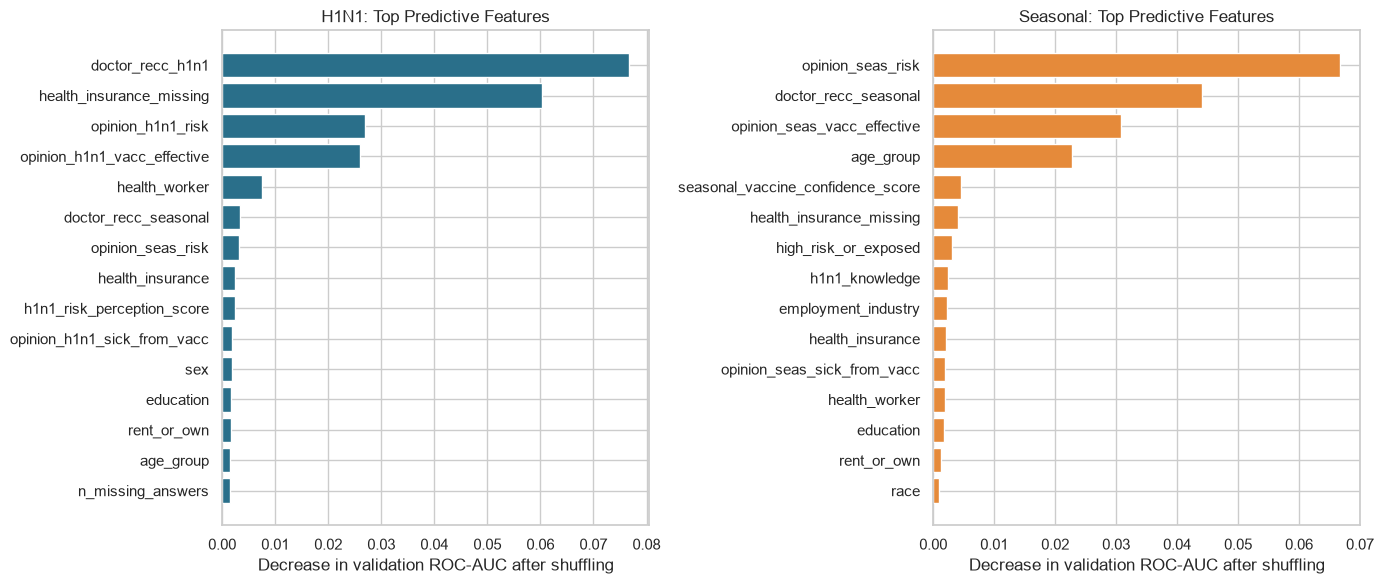

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for axis, target_name in zip(axes, ["H1N1", "Seasonal"]):
    top_features = importance_tables[target_name].head(15).sort_values("Importance")

    axis.barh(
        top_features["Feature"],
        top_features["Importance"],
        color="#2A6F8A" if target_name == "H1N1" else "#E58A3A"
    )

    axis.set_title(f"{target_name}: Top Predictive Features")
    axis.set_xlabel("Decrease in validation ROC-AUC after shuffling")

plt.tight_layout()
plt.show()

## STAGE 12: Save the Sprint 2 deliverables

The best fitted pipeline for each target includes both preprocessing and the selected classifier. Saving the complete pipeline ensures future data receives the same transformations before prediction.

In [25]:
saved_model_paths = {}

for target_name in ["H1N1", "Seasonal"]:
    model_name = best_model_names.loc[
        best_model_names["Target"].eq(target_name),
        "Model"
    ].iloc[0]

    fitted_pipeline = best_models[target_name][model_name]

    model_path = MODEL_DIR / f"best_{target_name.lower()}_pipeline.joblib"
    dump(fitted_pipeline, model_path)
    saved_model_paths[target_name] = model_path

# Save performance tables and feature-importance tables.
cv_results_df.to_csv(
    RESULTS_DIR / "baseline_cross_validation_results.csv",
    index=False
)

tuning_results_df.to_csv(
    RESULTS_DIR / "hyperparameter_tuning_results.csv",
    index=False
)

validation_results_df.to_csv(
    RESULTS_DIR / "validation_model_comparison.csv",
    index=False
)

importance_tables["H1N1"].to_csv(
    RESULTS_DIR / "h1n1_feature_importance.csv",
    index=False
)

importance_tables["Seasonal"].to_csv(
    RESULTS_DIR / "seasonal_feature_importance.csv",
    index=False
)

print("Saved model pipelines:")
for target_name, path in saved_model_paths.items():
    print(f"- {target_name}: {path}")

print("\nSaved result tables in:", RESULTS_DIR)

Saved model pipelines:
- H1N1: ../models/best_h1n1_pipeline.joblib
- Seasonal: ../models/best_seasonal_pipeline.joblib

Saved result tables in: ../results


## STAGE 13: Sprint 2 conclusions and presentation notes

Complete this section after running the notebook:

1. State the best H1N1 model and its validation ROC-AUC.
2. State the best seasonal model and its validation ROC-AUC.
3. Compare accuracy, precision, recall and F1.
4. Explain the most important predictors for each target.
5. Relate important predictors back to the Sprint 1 hypotheses.
6. Mention limitations:
   - feature importance does not prove causation;
   - survey answers are self-reported;
   - some predictors contain substantial missingness;
   - validation results estimate, but do not guarantee, performance on new populations.

### Suggested five-minute presentation

| Slide | Content |
|---|---|
| 1 | Problem, targets and Sprint 2 objective |
| 2 | Engineered features and preprocessing pipeline |
| 3 | Logistic Regression, Random Forest and Gradient Boosting comparison |
| 4 | Best ROC-AUC results and confusion matrices |
| 5 | Most important predictors, hypothesis findings and next steps |